# Paper figures

Fits and figures for the paper, made from one sample produced by `SampleSelection.ipynb`:

- **Inputs** (in `data/`): the sample (`final_sample_zsun0.fits` by default; change `SAMPLE_FILE` to use a variant) and its analysis cells (`<sample>_cells.ecsv`).
- **Cached fits** (in `data/`): `sech2_fits_cells_<sample>.pkl` (one fit per cell) and `sech2_fits_flare_0.5kpc_<sample>.pkl` (one fit per radial bin). They are refit automatically when the stars, the cells or the fit settings change; set `FORCE_RERUN = True` to refit anyway (e.g. after changing the model priors).
- **Figures** go to `figures/`.

Sections:
1. [Mg/Fe] vs z in two example cells
2. The midplane height z0 in every cell
3. The effective thickness h_eff vs R
4. The warp model fit to z0
5. The warp compared with the literature

In [1]:
import hashlib
import pickle
from pathlib import Path

import corner
import jax
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
from astropy.table import Table
from matplotlib.collections import PolyCollection
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from matplotlib.ticker import AutoMinorLocator
from numpyro.diagnostics import print_summary
from numpyro.infer import MCMC, NUTS, init_to_value
from tqdm import tqdm

from midplane.cells import EXAMPLE_POINTS, SUN_POINT, assign, outline
from midplane.midplane_model import bin_one, fit_sech2, mixture_of_sech2, model_z0

numpyro.set_host_device_count(4)  # run MCMC chains in parallel on CPU

In [2]:
# --- files --------------------------------------------------------------------
REPO_ROOT = Path.cwd().parent  # this notebook lives in <repo>/notebooks/
DATA_DIR = REPO_ROOT / "data"
SAMPLE_FILE = DATA_DIR / "final_sample_zsun0.fits"  # CHANGE to use a sample variant
CELLS_FILE = SAMPLE_FILE.with_name(
    SAMPLE_FILE.stem + "_cells.ecsv"
)  # from SampleSelection.ipynb
FIG_DIR = REPO_ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)
FORCE_RERUN = False  # True = ignore the cached fits and refit everything

# --- sech^2 fits of the vertical [Mg/Fe] profile (in cells and in radial bins) -----
Z_BINS_FIT = np.arange(-5, 5 + 1e-3, 0.1)  # z bins for the binned [Mg/Fe] means [kpc]
Z_FIT_RANGE = (-1.5, 1.5)  # only z bins in this range are fit [kpc]
MIN_PER_ZBIN_FIT = 5  # stars needed in a z bin
MIN_ZBINS_FIT = 8  # usable z bins needed to fit
MIN_STARS_RBIN = 15  # stars needed in a radial bin (cells come with >= 50)
# part of the cache keys; the sech^2 model and its priors are model_z0 in src/midplane/midplane_model.py
# (set FORCE_RERUN = True after changing them)
FIT_SETTINGS = (
    Z_BINS_FIT.tolist(),
    Z_FIT_RANGE,
    MIN_PER_ZBIN_FIT,
    MIN_ZBINS_FIT,
    MIN_STARS_RBIN,
)
H_EFF_DROP = (
    0.02  # "fixed rise" h_eff: where the dip has risen this much above its minimum
)

# --- figures --------------------------------------------------------------------
R_SUN = 8.275  # kpc
ZLIM = 0.6  # z0 colour range in the polar maps [kpc]
R_TICKS, EXTRA_R_TICKS = [4, 8, 12, 16], [2, 6, 10, 14]
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "savefig.dpi": 300,
        "savefig.bbox": "tight",
        "font.size": 12,
        "axes.labelsize": 13,
    }
)

In [3]:
# =============================================================================
# Plotting helpers
# =============================================================================
def to_sun_frame_deg(phi_rad):
    """arctan2(y, x) azimuth (Sun at 180 deg) -> Sun at 0, positive clockwise, in [-180, 180)."""
    d = 180.0 - np.degrees(phi_rad)
    return (d + 180.0) % 360.0 - 180.0


def cell_label(c):
    """R and azimuth range of a cell (a row of the cell table); azimuth with the Sun at 0, clockwise."""
    a, b = to_sun_frame_deg(c["phi_hi"]), to_sun_frame_deg(c["phi_lo"])
    return f"${c['R_lo']:.1f} \\leq R < {c['R_hi']:.1f}$ kpc, $\\phi$ = {a:+.1f} to {b:+.1f}$^\\circ$"


def style_axes(ax, grid=True):
    """Minor ticks, inward ticks on all four sides, and (optionally) a light major grid."""
    ax.xaxis.set_minor_locator(AutoMinorLocator())
    ax.yaxis.set_minor_locator(AutoMinorLocator())
    ax.tick_params(which="major", length=6, direction="in", top=True, right=True)
    ax.tick_params(which="minor", length=3, direction="in", top=True, right=True)
    if grid:
        ax.grid(which="major", color="0.85", linestyle="-", linewidth=0.6, zorder=0)


def polar_cells(ax, rows, values, cmap, vmin, vmax, label):
    """Fill cells (rows of the cell table) on a polar axis with colours from values, plus the Sun.
    Azimuth is drawn with the Sun at 0 deg, positive clockwise."""
    verts = []
    for c in rows:
        R_c, phi_c = outline(c)
        verts.append(np.c_[np.radians(to_sun_frame_deg(phi_c)), R_c])
    pc = PolyCollection(
        verts,
        array=np.asarray(values, float),
        cmap=cmap,
        edgecolors="face",
        linewidths=0.3,
    )
    pc.set_clim(vmin, vmax)
    ax.add_collection(pc)
    ax.figure.colorbar(pc, ax=ax, pad=0.01, shrink=0.7).set_label(label, fontsize=17)
    theta_lim = np.sort(
        to_sun_frame_deg(np.array([cells["phi_lo"].min(), cells["phi_hi"].max()]))
    )
    ax.set_theta_zero_location("W")
    ax.set_theta_direction(-1)
    ax.set_rmax(float(cells["R_hi"].max()))
    ax.set_thetamin(theta_lim[0])
    ax.set_thetamax(theta_lim[1])
    ax.set_rgrids(R_TICKS, labels=[f"{r} kpc" for r in R_TICKS], fontsize=11)
    ax.set_yticks(EXTRA_R_TICKS, minor=True)
    ax.yaxis.grid(True, which="minor", color="0.85", linestyle="-", linewidth=0.5)
    ax.plot(
        0.0,
        R_SUN,
        marker="*",
        color="yellow",
        markersize=14,
        markeredgecolor="k",
        zorder=5,
        label="Sun",
    )

In [4]:
# =============================================================================
# The vertical [Mg/Fe] profile: two-component sech^2 dip, its fit, and h_eff
# =============================================================================
def bin_for_fit(z, mgfe, mgfe_err):
    """Binned profile of these stars, keeping only the z bins the fit uses; None if too few remain."""
    zc, mean, err, cnt = bin_one(z, mgfe, mgfe_err, z_bins=Z_BINS_FIT)
    good = (
        np.isfinite(mean)
        & np.isfinite(err)
        & (cnt >= MIN_PER_ZBIN_FIT)
        & (zc >= Z_FIT_RANGE[0])
        & (zc <= Z_FIT_RANGE[1])
    )
    if good.sum() < MIN_ZBINS_FIT:
        return None
    return zc[good].astype(float), mean[good].astype(float), err[good].astype(float)


def posterior_curves(s, zg):
    """Model [Mg/Fe](z) on the grid zg for every posterior sample, shape (n_samples, len(zg))."""
    A1, A2, h1, h2, z0 = (
        np.asarray(s[k])[:, None] for k in ("A1", "A2", "h1", "h2", "z0")
    )
    return (
        np.asarray(mixture_of_sech2(zg[None, :], A1, A2, h1, h2, z0))
        + np.asarray(s["offset"])[:, None]
    )


def data_hash(*arrays):
    """Short fingerprint of the values in these arrays, for cache keys."""
    h = hashlib.sha1()
    for a in arrays:
        h.update(np.ascontiguousarray(a).tobytes())
    return h.hexdigest()


def cached_fits(path, key, fit_all):
    """The fits saved at path if they were made with the same key; otherwise run fit_all() and save."""
    if path.exists() and not FORCE_RERUN:
        with open(path, "rb") as f:
            saved = pickle.load(f)
        if saved.get("key") == key:
            print(f"loaded {path.name}")
            return saved["fits"]
        print(
            f"{path.name} was made for a different sample, cells or fit settings; refitting"
        )
    fits = fit_all()
    tmp = path.with_suffix(
        ".tmp"
    )  # write then rename, so an interrupted save leaves no broken file
    with open(tmp, "wb") as f:
        pickle.dump({"key": key, "fits": fits}, f)
    tmp.replace(path)
    print(f"saved {path}")
    return fits


# --- h_eff: three ways to measure the half-thickness of the dip, for every posterior sample ---
K_INFL = np.arctanh(1 / np.sqrt(3))  # 0.658: inflection of a single sech^2(u)
d2_jax = jax.grad(jax.grad(mixture_of_sech2, argnums=0), argnums=0)  # f''(z)
d2_vec = jax.jit(jax.vmap(d2_jax))  # arguments: z, A1, A2, h1, h2, z0 (all arrays)


def _params(s):
    return (jnp.asarray(np.asarray(s[k])) for k in ("A1", "A2", "h1", "h2", "z0"))


def inflection_height(s, n_iter=40):
    """h_eff = z_infl - z0, where f''(z_infl) = 0 (bisection on f'' from jax.grad)."""
    A1, A2, h1, h2, z0 = _params(s)
    lo = z0 + K_INFL * h1  # f'' > 0 here
    hi = z0 + K_INFL * h2  # f'' < 0 here (h2 > h1)
    for _ in range(n_iter):
        mid = 0.5 * (lo + hi)
        pos = d2_vec(mid, A1, A2, h1, h2, z0) > 0
        lo = jnp.where(pos, mid, lo)
        hi = jnp.where(pos, hi, mid)
    return np.asarray(0.5 * (lo + hi) - z0)


def crossing_height(s, kind, n_iter=50):
    """z - z0 where the dip profile (no offset) reaches a target level.
    kind = "half":  target = half of the dip depth, 0.5 * (A1 + A2)
    kind = "fixed": target = trough + H_EFF_DROP, i.e. the profile has risen that much above its minimum
    Samples whose profile never reaches the target return NaN."""
    A1, A2, h1, h2, z0 = _params(s)
    trough = A1 + A2  # profile value at z0 (negative)
    target = 0.5 * trough if kind == "half" else trough + H_EFF_DROP
    lo = z0  # profile is below target here
    hi = z0 + 8 * jnp.maximum(h1, h2)  # profile has recovered to ~0 here
    reaches = mixture_of_sech2(hi, A1, A2, h1, h2, z0) > target
    for _ in range(n_iter):  # the profile rises monotonically for z > z0
        mid = 0.5 * (lo + hi)
        below = mixture_of_sech2(mid, A1, A2, h1, h2, z0) < target
        lo = jnp.where(below, mid, lo)
        hi = jnp.where(below, hi, mid)
    return np.where(np.asarray(reaches), np.asarray(0.5 * (lo + hi) - z0), np.nan)


def percentile_summary(h):
    """Median and half the 16-84th percentile range of the finite values, and how many there are."""
    h = h[np.isfinite(h)]
    if len(h) == 0:
        return np.nan, np.nan, 0
    p16, p50, p84 = np.percentile(h, [16, 50, 84])
    return p50, 0.5 * (p84 - p16), len(h)


# sanity check: jax's f'' agrees with the closed form for a sum of sech^2 terms
def _d2f_analytic(z, A1, A2, h1, h2, z0):
    t1, t2 = np.tanh((z - z0) / h1), np.tanh((z - z0) / h2)
    return A1 / h1**2 * (1 - t1**2) * (6 * t1**2 - 2) + A2 / h2**2 * (1 - t2**2) * (
        6 * t2**2 - 2
    )


_p = dict(z=0.31, A1=-0.05, A2=-0.03, h1=0.2, h2=0.6, z0=0.01)
assert np.isclose(float(d2_jax(*_p.values())), _d2f_analytic(*_p.values()), rtol=1e-3)

In [5]:
# =============================================================================
# The warp model fit to the cell z0 values
# =============================================================================
# z_warp(R, phi) = A(R) sin(phi - phi_LON(R)) + z_off, with
# A(R) = h_w0 [(R - R_w) / (R_NORM - R_w)]^alpha_w for R > R_w (0 inside), and
# phi_LON(R) = phiLON0, twisting at beta_w deg/kpc beyond R_t in the twisted model.
# The amplitude is normalized at 12 kpc (outside R_w, where the signal is larger),
# which made sampling easier than normalizing at R_sun.
R_NORM = 12.0  # kpc
warp_param_names = ["h_w0", "R_w", "alpha_w", "phiLON0", "R_t", "beta_w"]

labels_map = {
    "h_w0": r"$h_{w}\ [{\rm kpc}]$",
    "z_off": r"$z_{\rm off}$ [kpc]",
    "s": r"$s$ [kpc]",
    "R_w": r"$R_w$ [kpc]",
    "alpha_w": r"$\alpha_w$",
    "phiLON0": r"$\phi_{\rm LON,0}$ [deg]",
    "R_t": r"$R_t$ [kpc]",
    "beta_w": r"$\beta_w$ [deg/kpc]",
}


def warp_amp_phase(R, R_w, alpha_w, phiLON0, h_w0, R_t=None, beta_w=None):
    """Warp amplitude A(R) [kpc] and line of nodes phi_LON(R) [deg]."""
    # the inner where() keeps 0**alpha out of the graph (its gradient wrt alpha is NaN inside R_w)
    ratio = (R - R_w) / (R_NORM - R_w)
    A = jnp.where(ratio > 0, h_w0 * jnp.where(ratio > 0, ratio, 1.0) ** alpha_w, 0.0)
    phiLON = phiLON0 + 0.0 * R
    if R_t is not None:
        phiLON = phiLON0 + beta_w * jnp.maximum(R - R_t, 0.0)
    return A, phiLON


def warp_z(R, phi, **params):
    """warp height z = A(R) sin(phi - phiLON(R))"""
    A, phiLON = warp_amp_phase(R, **params)
    return A * jnp.sin(phi - jnp.radians(phiLON))


def poggio_h_w0(samples):
    """convert our amplitude parameter to Poggio's definition."""
    return samples["h_w0"] / (R_NORM - samples["R_w"]) ** samples["alpha_w"]


def z_model(R, phi, p):
    """Full model height: m=1 warp + global offset."""
    return warp_z(R, phi, **{k: p[k] for k in warp_param_names if k in p}) + p.get(
        "z_off", 0.0
    )


def sample_warp_params(twisted=False):
    """Sample the m=1 warp parameters; optionally include the twist."""
    p = {
        "h_w0": numpyro.sample("h_w0", dist.Uniform(1e-4, 2.0)),
        "R_w": numpyro.sample("R_w", dist.Uniform(3.0, R_NORM)),
        "alpha_w": numpyro.sample("alpha_w", dist.Uniform(0.1, 5.0)),
        "phiLON0": numpyro.sample("phiLON0", dist.Normal(0, 45.0)),  # deg, weak prior
    }
    if twisted:
        p["R_t"] = numpyro.sample(
            "R_t", dist.Uniform(p["R_w"], 16.0)
        )  # twist starts outside R_w
        p["beta_w"] = numpyro.sample("beta_w", dist.Uniform(-30.0, 30.0))  # deg / kpc
    return p


def warp_model(
    R,
    phi,
    cell,
    w,
    z0_err,
    z0=None,
    twisted=False,
    offset=True,
    jitter=True,
    z_off_fixed=None,
):
    """numpyro model for the warp, one z0 per cell.

    R, phi are the positions of stars in the cells, cell (0 .. len(z0_err) - 1) says which
    cell each is in and w = 1 / (stars in that cell): a cell's model z0 is the model height
    averaged over its stars, so large cells are compared with the warp where their stars are.
    z_off_fixed fixes the global offset; offset=True fits it."""
    p = sample_warp_params(twisted=twisted)

    if z_off_fixed is not None:
        p["z_off"] = numpyro.deterministic("z_off", jnp.asarray(z_off_fixed))
    elif offset:
        p["z_off"] = numpyro.sample("z_off", dist.Normal(0.0, 0.1))

    sigma = z0_err
    if jitter:  # intrinsic scatter of the cell z0 about the smooth model
        s = numpyro.sample("s", dist.HalfNormal(0.1))
        sigma = jnp.sqrt(z0_err**2 + s**2)

    z_cell = jax.ops.segment_sum(
        w * z_model(R, phi, p), cell, num_segments=z0_err.shape[0]
    )
    numpyro.sample("z0", dist.Normal(z_cell, sigma), obs=z0)


def run_warp_fit(data, num_warmup=1000, num_samples=2000, seed=0, **model_kwargs):
    """Run NUTS and return posterior samples. data needs keys R, phi, cell, w, z0, z0_err."""
    init = {
        "alpha_w": 1.5,
        "phiLON0": 0.0,
        "z_off": 0.0,
        "s": 0.03,
        "h_w0": 0.3,
        "R_w": 7.0,
    }
    if model_kwargs.get("twisted", False):
        init.update(R_t=11.0, beta_w=0.0)

    mcmc = MCMC(
        NUTS(warp_model, init_strategy=init_to_value(values=init)),
        num_warmup=num_warmup,
        num_samples=num_samples,
        num_chains=4,
    )
    mcmc.run(
        jax.random.PRNGKey(seed), **data, **model_kwargs, extra_fields=("diverging",)
    )
    print_summary(mcmc.get_samples(group_by_chain=True))
    print(f"Number of divergences: {mcmc.get_extra_fields()['diverging'].sum()}")
    return {k: np.asarray(v) for k, v in mcmc.get_samples().items()}


def summarize_warp(samples, label):
    """Median and 1-sigma range of each parameter, next to the Poggio+25 young-giant value."""
    print(f"\n{label}")
    print(
        f"{'parameter':<10s} {'median':>9s} {'-1sig':>8s} {'+1sig':>8s} {'Poggio YG':>10s}"
    )
    rows = dict(samples)
    rows["h_w0"] = poggio_h_w0(samples)  # amplitude in Poggio's definition
    for k in ["h_w0", "R_w", "alpha_w", "phiLON0", "R_t", "beta_w", "z_off", "s"]:
        if k not in rows:
            continue
        lo, med, hi = np.percentile(rows[k], [16, 50, 84])
        ref = f"{POGGIO_YG[k]:>10.3g}" if k in POGGIO_YG else f"{'':>10s}"
        print(f"{k:<10s} {med:>9.3f} {med - lo:>8.3f} {hi - med:>8.3f} {ref}")


def median_params(samples):
    """Posterior medians, shaped like a one-sample posterior."""
    return {k: np.array([np.median(v)]) for k, v in samples.items()}


def warp_curves(samples, R, twisted):
    """Amplitude h_w(R) and line of nodes phi_LON(R) for every posterior sample, shape (n_samples, len(R))."""
    keys = ["R_w", "alpha_w", "phiLON0", "h_w0"] + (
        ["R_t", "beta_w"] if twisted else []
    )
    p = {k: np.asarray(samples[k]).reshape(-1, 1) for k in keys}
    A, phi = warp_amp_phase(R[None, :], **p)
    A = np.asarray(A)
    return A, np.asarray(phi) + 0.0 * A


def corner_plot(samples, names=None, color=None, **kwargs):
    kwargs = {"show_titles": True, "quantiles": [0.16, 0.5, 0.84], **kwargs}
    if names is None:
        names = list(samples.keys())
    with plt.rc_context({"figure.constrained_layout.use": False}):
        fig = corner.corner(
            np.stack([samples[k] for k in names], axis=-1),
            labels=[labels_map.get(k, "") for k in names],
            color=color,
            levels=1 - np.exp(-0.5 * np.array([1.0, 2.0]) ** 2),
            smooth=1.0,
            bins=40,
            plot_datapoints=False,
            fill_contours=True,
            hist_kwargs={"density": True, "lw": 1.5},
            title_fmt=".3g",
            max_n_ticks=4,
            **kwargs,
        )

    # left-align the diagonal titles so they extend into the empty upper triangle
    n = len(names)
    axes = np.array(fig.axes).reshape(n, n)
    for i in range(n):
        t = axes[i, i].title
        t.set_ha("left")
        t.set_x(0.0)
    return fig


def corner_vs_reference(samples, names, ref, color="tab:orange"):
    """Corner plot with reference values (dict, by parameter name) drawn as lines and squares;
    axes are widened so every reference value is visible. Returns the figure and its axes grid."""
    fig = corner_plot(samples, names=names)
    n = len(names)
    axes = np.array(fig.axes).reshape(n, n)
    truth = np.array([ref.get(k, np.nan) for k in names], float)

    for i in range(n):
        for j in range(i + 1):
            ax = axes[i, j]
            if np.isfinite(truth[j]):
                ax.axvline(truth[j], color=color, lw=2 if i == j else 1.2)
            if i != j and np.isfinite(truth[i]):
                ax.axhline(truth[i], color=color, lw=1.2)
            if i != j and np.isfinite(truth[i]) and np.isfinite(truth[j]):
                ax.plot(truth[j], truth[i], "s", color=color, ms=8, mec="k", zorder=10)

    for k in range(n):
        if not np.isfinite(truth[k]):
            continue
        lo, hi = axes[n - 1, k].get_xlim()
        lo, hi = min(lo, truth[k]), max(hi, truth[k])
        pad = 0.05 * (hi - lo)
        for r in range(k, n):  # column k: x axis
            axes[r, k].set_xlim(lo - pad, hi + pad)
        for c in range(0, k):  # row k: y axis
            axes[k, c].set_ylim(lo - pad, hi + pad)
    return fig, axes

In [6]:
# =============================================================================
# Published warp measurements, for comparison
# =============================================================================
def h_w_paper(R, R_w, h_w0, alpha_w):
    """Poggio+25 amplitude: h_w0 (R - R_w)^alpha_w outside R_w."""
    return np.where(R > R_w, h_w0 * np.clip(R - R_w, 0, None) ** alpha_w, 0.0)


def phiLON_paper(R, phiLON0, R_t, beta_w):
    return np.where(R <= R_t, phiLON0, phiLON0 + beta_w * (R - R_t))


def A_uppal(R, C_w=0.0057, R_w=7.4, eps_w=1.40):
    return C_w * np.clip(R * 1000.0 - R_w * 1000.0, 0, None) ** eps_w / 1000.0


def A_lopez(R, C_w=1.2e-3, exp=5.25):
    return C_w * np.clip(R, 0, None) ** exp / 1000.0


def A_yusifov(R, C_w=37.0, R_w=6.5, b_w=1.4, R_WS=15.2):
    return C_w * np.clip(np.minimum(R, R_WS) - R_w, 0, None) ** b_w / 1000.0


yg = dict(
    R_w=5.5, h_w0=0.012, alpha_w=1.9, phiLON0=0.1, R_t=12.1, beta_w=9.9
)  # Poggio+25 young giants
ceph = dict(
    R_w=7.7, h_w0=0.057, alpha_w=1.3, phiLON0=0.9, R_t=12.6, beta_w=8.0
)  # Poggio+25 Cepheids
yg_straight_phiLON, ceph_straight_phiLON = 9.9, 14.0  # their straight-LON fits
khanna = dict(h_w0=0.194, R_w=9.30, alpha_w=1.5, phiLON0=2.0)  # Case I
uppal = dict(C_w=0.0057, R_w=7.4, eps_w=1.40, phiLON0=2.03)
lopez = dict(C_w=1.2e-3, exp=5.25, phiLON0=-5.0)
yusifov = dict(C_w=37.0, R_w=6.5, b_w=1.4, R_WS=15.2, phiLON0=14.5)  # sign-flipped
POGGIO_YG = yg  # the main comparison
LIT_COLORS = {
    "Poggio+25 young giants": "cyan",
    "Poggio+25 cepheids": "deepskyblue",
    "Khanna+25 (RC)": "red",
    "Uppal+24 (RC)": "salmon",
    "López-Corredoira+02 (RC)": "indianred",
    "Yusifov+04 (pulsars)": "gray",
}

# amplitude at 12 kpc, which is what our h_w0 parameter measures
A12 = {
    "Poggio+25 young giants": float(
        h_w_paper(np.array(12.0), yg["R_w"], yg["h_w0"], yg["alpha_w"])
    ),
    "Poggio+25 cepheids": float(
        h_w_paper(np.array(12.0), ceph["R_w"], ceph["h_w0"], ceph["alpha_w"])
    ),
    "Khanna+25 (RC)": float(
        h_w_paper(np.array(12.0), khanna["R_w"], khanna["h_w0"], khanna["alpha_w"])
    ),
    "Uppal+24 (RC)": float(A_uppal(12.0, uppal["C_w"], uppal["R_w"], uppal["eps_w"])),
    "López-Corredoira+02 (RC)": float(A_lopez(12.0, lopez["C_w"], lopez["exp"])),
    "Yusifov+04 (pulsars)": float(
        A_yusifov(12.0, yusifov["C_w"], yusifov["R_w"], yusifov["b_w"], yusifov["R_WS"])
    ),
}

## 1. The sample, and [Mg/Fe] vs z in two example cells

The fits use every star with a finite, positive [Mg/Fe] error, the same stars `SampleSelection.ipynb` counted when it built the cells; the check below stops if the cell table does not match this sample. The figure shows the vertical [Mg/Fe] profile in the two cells containing `midplane.cells.EXAMPLE_POINTS`, on either side of the Sun.

In [7]:
t = Table.read(SAMPLE_FILE)
cells = Table.read(CELLS_FILE)
print(
    f"Loaded {len(t):,} stars and {len(cells)} cells ({int(cells['ok'].sum())} usable)"
)
for c in ["dist_kpc", "R_gc_kpc", "z_gc_kpc", "mgfe", "snr_used"]:
    v = np.asarray(t[c], float)
    print(
        f"{c:<10} min {np.nanmin(v):8.3f}  median {np.nanmedian(v):8.3f}  max {np.nanmax(v):8.3f}"
    )

# --- every star, and the stars the fits use ---
R_all = np.asarray(t["R_gc_kpc"], float)
phi_all = np.mod(
    np.asarray(t["phi_gc_rad"], float), 2 * np.pi
)  # arctan2 gives [-pi, pi]
Z_all = np.asarray(t["z_gc_kpc"], float)
mgfe_all = np.asarray(t["mgfe"], float)
err_all = np.asarray(t["mgfe_err"], float)
cell_all = assign(cells, R_all, phi_all)  # cell_id of each star, -1 outside

use = (
    np.isfinite(R_all)
    & np.isfinite(Z_all)
    & np.isfinite(mgfe_all)
    & np.isfinite(err_all)
    & (err_all > 0)
)  # same stars SampleSelection built the cells from
R_star, Z_star, phi_star = R_all[use], Z_all[use], phi_all[use]
mgfe_star, err_star, cell_star = mgfe_all[use], err_all[use], cell_all[use]
n_in_cell = np.bincount(cell_star[cell_star >= 0], minlength=len(cells))
assert (n_in_cell == cells["n_stars"]).all(), (
    "cells do not match this sample: rerun SampleSelection.ipynb"
)

fit_cells = cells[cells["ok"]]
print(
    f"stars used for the fits: {use.sum():,}; {len(fit_cells)} usable cells hold "
    f"{int(fit_cells['n_stars'].sum()):,} of them"
)

Loaded 362,887 stars and 120 cells (110 usable)
dist_kpc   min    0.065  median    2.191  max   42.331
R_gc_kpc   min    0.058  median    9.096  max   38.110
z_gc_kpc   min  -23.964  median   -0.013  max   17.295
mgfe       min   -0.199  median    0.010  max    0.180
snr_used   min   19.473  median  130.366  max 3290.690
stars used for the fits: 353,151; 110 usable cells hold 347,595 of them


cell 63: 2,349 stars
cell 39: 4,632 stars


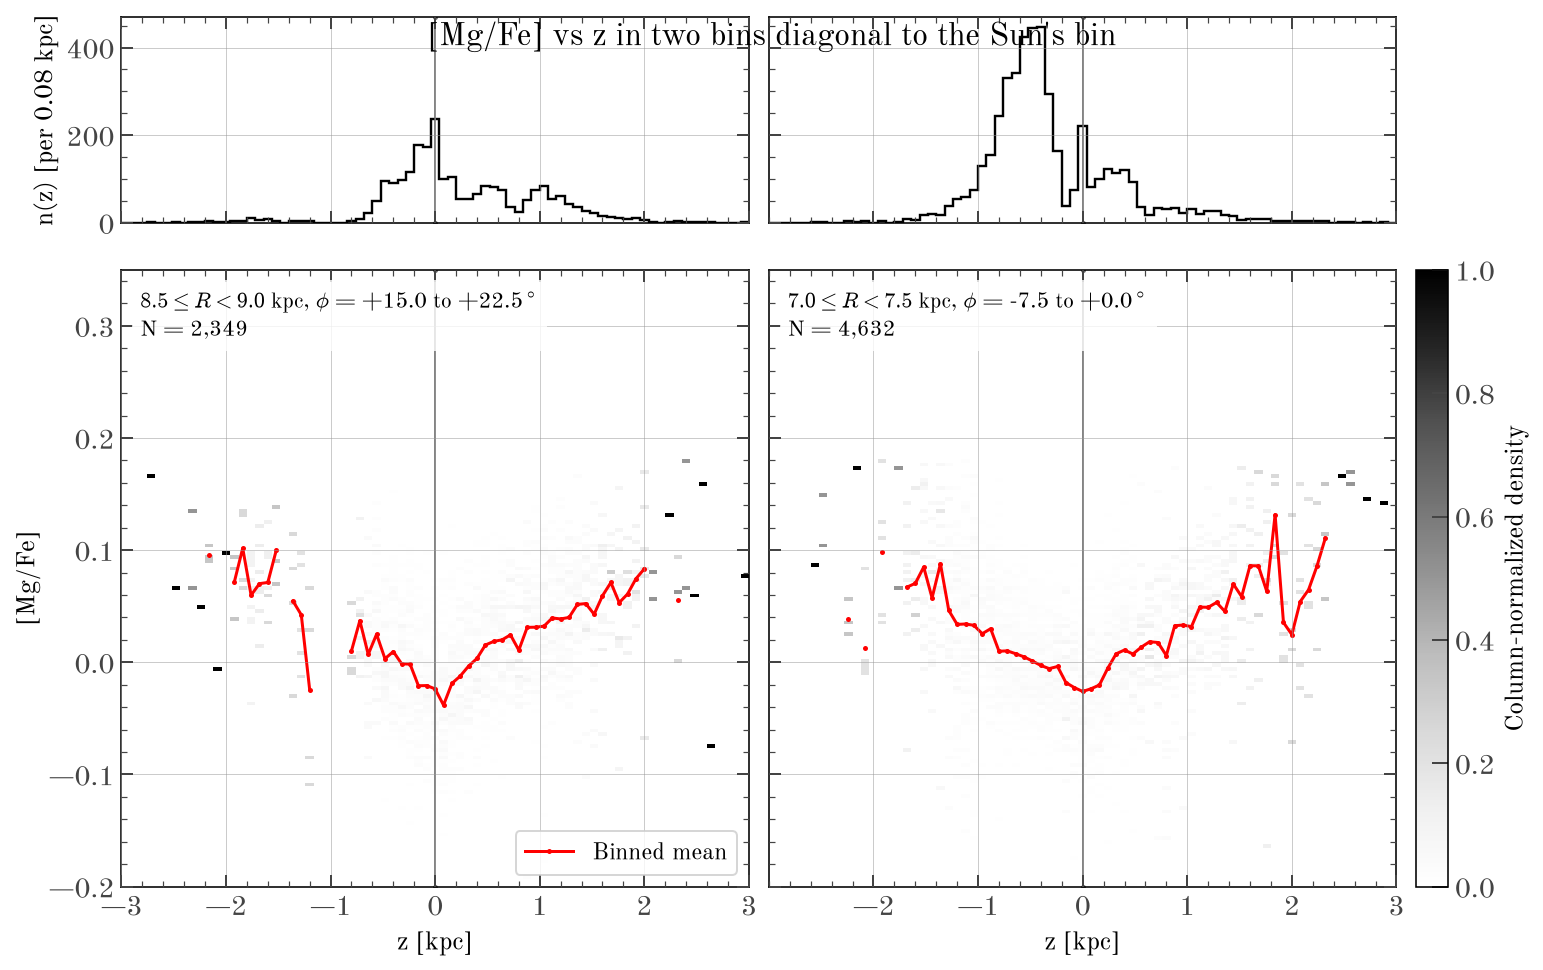

In [8]:
Z_LIM, MGFE_LIM = 3.0, (-0.2, 0.35)
DZ, N_MGFE_BINS = 0.08, 160  # z bin width [kpc], [Mg/Fe] bins for the map
MIN_PER_ZBIN = 3  # need this many stars to draw a mean point

ex_R, ex_phi = np.transpose(EXAMPLE_POINTS)
ex_cids = assign(cells, ex_R, np.deg2rad(ex_phi))
assert (ex_cids >= 0).all(), "an EXAMPLE_POINT is outside every cell"

z_edges = np.arange(-Z_LIM, Z_LIM + DZ / 2, DZ)
z_cent = 0.5 * (z_edges[:-1] + z_edges[1:])
m_edges = np.linspace(*MGFE_LIM, N_MGFE_BINS + 1)

# --- pass 1: density map, mean line and n(z) for each cell ----------------------
panels = []
for cid in ex_cids:
    sel = cell_star == cid
    z, m = Z_star[sel], mgfe_star[sel]

    H, _, _ = np.histogram2d(z, m, bins=[z_edges, m_edges])
    colsum = H.sum(axis=1, keepdims=True)
    Hn = np.divide(H, colsum, out=np.zeros_like(H), where=colsum > 0)

    idx = np.digitize(z, z_edges) - 1
    ok = (idx >= 0) & (idx < len(z_cent))
    n_bin = np.bincount(idx[ok], minlength=len(z_cent))
    sum_m = np.bincount(idx[ok], weights=m[ok], minlength=len(z_cent))
    mean = np.where(n_bin >= MIN_PER_ZBIN, sum_m / np.maximum(n_bin, 1), np.nan)

    panels.append(dict(cell=cells[cid], Hn=Hn, mean=mean, nz=n_bin, N=int(sel.sum())))
    print(f"cell {cid}: {sel.sum():,} stars")

vmax = max(p["Hn"].max() for p in panels)
nmax = max(p["nz"].max() for p in panels)

# --- pass 2: 2 rows x (panels + colorbar column), no gap between panels --------
n = len(panels)
fig = plt.figure(figsize=(4.8 * n + 1.0, 6.6))
gs = fig.add_gridspec(
    2,
    n + 1,
    height_ratios=[1, 3],
    width_ratios=[1] * n + [0.05],
    hspace=0.04,
    wspace=0.0,
    top=0.92,
)
ax_top = [fig.add_subplot(gs[0, i]) for i in range(n)]
ax_bot = [fig.add_subplot(gs[1, i]) for i in range(n)]
cax = fig.add_subplot(gs[1, n])

for i, p in enumerate(panels):
    at, ab = ax_top[i], ax_bot[i]

    # top: n(z)
    at.stairs(p["nz"], z_edges, color="k", lw=1.2)
    at.set_ylim(0, 1.05 * nmax)

    # bottom: column-normalized density + binned mean
    im = ab.pcolormesh(
        z_edges, m_edges, p["Hn"].T, cmap="Greys", norm=Normalize(vmin=0, vmax=vmax)
    )
    ab.plot(
        z_cent, p["mean"], color="red", lw=1.5, label="Binned mean" if i == 0 else None
    )
    ab.set_ylim(*MGFE_LIM)
    ab.set_xlabel("z [kpc]")
    ab.text(
        0.03,
        0.97,
        f"{cell_label(p['cell'])}\nN = {p['N']:,}",
        transform=ab.transAxes,
        va="top",
        ha="left",
        fontsize=11,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.8),
    )

    for a in (at, ab):
        a.axvline(0, color="0.4", lw=0.8)
        a.set_xlim(-Z_LIM, Z_LIM)
        a.set_xticks(np.arange(-Z_LIM, Z_LIM + 1, 1)[(0 if i == 0 else 1) :])
        style_axes(a, grid=False)
        a.set_axisbelow(False)  # draw the grid above the density map
        a.grid(which="major", color="0.6", linestyle="-", linewidth=0.5, alpha=0.5)
    at.tick_params(labelbottom=False)
    if i > 0:  # shared y on the inner panels
        at.tick_params(labelleft=False)
        ab.tick_params(labelleft=False)

ax_top[0].set_ylabel(f"n(z) [per {DZ:g} kpc]")
ax_bot[0].set_ylabel("[Mg/Fe]")
ax_bot[0].legend(loc="lower right")
fig.colorbar(im, cax=cax).set_label("Column-normalized density")
fig.suptitle("[Mg/Fe] vs z in two bins diagonal to the Sun's bin", fontsize=16, y=0.99)
fig.savefig(FIG_DIR / "mgfe_vs_z_two_bins.pdf", bbox_inches="tight")
fig.savefig(FIG_DIR / "mgfe_vs_z_two_bins.png", dpi=300, bbox_inches="tight")
plt.show()

## 2. The midplane height z0 in every cell

In each usable cell, the stars' [Mg/Fe] is averaged in 0.1 kpc z bins and a two-component sech² dip plus offset is fit to the binned profile; z0 is the centre of the dip. The model and its priors are `model_z0` in `src/midplane/midplane_model.py`.

In [ ]:
def fit_every_cell():
    per_cell = {}
    key = jr.PRNGKey(0)
    for k, cid in enumerate(fit_cells["cell_id"], 1):
        m = cell_star == cid
        data = bin_for_fit(Z_star[m], mgfe_star[m], err_star[m])
        if data is not None:
            try:
                key, sub = jr.split(key)
                samples = fit_sech2(*data, sub, model_z0).get_samples()
                per_cell[int(cid)] = {
                    "n_stars": int(m.sum()),
                    "z_binc": data[0],
                    "mean": data[1],
                    "err": data[2],
                    "z0_med": float(np.median(samples["z0"])),
                    "z0_std": float(np.std(samples["z0"])),
                    "samples": {kk: np.asarray(vv[::2]) for kk, vv in samples.items()},
                }  # every other draw, both chains
            except Exception as e:
                print(f"  fit failed: cell {cid} -> {e}")
        if k % 20 == 0 or k == len(fit_cells):
            print(
                f"  {k}/{len(fit_cells)} cells done, {len(per_cell)} fit so far",
                flush=True,
            )
    return per_cell


# the cached fits are reused only for the same stars, cells and fit settings
cells_key = (
    data_hash(Z_star, mgfe_star, err_star, cell_star),
    FIT_SETTINGS,
    np.array([fit_cells[k] for k in ("R_lo", "R_hi", "phi_lo", "phi_hi")]).T.tolist(),
)
per_cell = cached_fits(
    DATA_DIR / f"sech2_fits_cells_{SAMPLE_FILE.stem}.pkl", cells_key, fit_every_cell
)
print(f"{len(per_cell)} of {len(fit_cells)} usable cells fit")

# z0 summary per usable cell (NaN where the fit was skipped or failed)
for k in ("z0_med", "z0_std"):
    fit_cells[k] = [
        per_cell[c][k] if c in per_cell else np.nan for c in fit_cells["cell_id"]
    ]

/Users/aprice-whelan/projects/chemical-midplane/src/midplane/midplane_model.py:163: RuntimeWarning: invalid value encountered in divide
  mean_tracer = stat1.statistic / stat2.statistic
/Users/aprice-whelan/projects/chemical-midplane/src/midplane/midplane_model.py:164: RuntimeWarning: divide by zero encountered in divide
  mean_tracer_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter ** 2)


In [ ]:
# Every fitted cell, ordered by R then azimuth (azimuth: Sun at 0 deg, positive clockwise)
N_DRAWS = 30  # posterior draws drawn per panel
Z_PLOT = 2.0  # x range is +/- this [kpc]
YLIM = None  # e.g. (-0.1, 0.3); None = set from the data
N_COLS = 10  # panels per row
PANEL_W, PANEL_H = 1.9, 1.45  # inches per panel
OUT_STEM = FIG_DIR / "sech2_fits_all_bins"

fitted = [row for row in fit_cells if row["cell_id"] in per_cell]
n_rows = -(-len(fitted) // N_COLS)

means = np.concatenate([per_cell[k]["mean"] for k in per_cell])
if YLIM is None:
    lo, hi = np.percentile(means, [0.5, 99.5])
    YLIM = (lo - 0.04, hi + 0.06)

zg = np.linspace(-Z_PLOT, Z_PLOT, 200)
rng = np.random.default_rng(0)

fig, axes = plt.subplots(
    n_rows,
    N_COLS,
    figsize=(PANEL_W * N_COLS, PANEL_H * n_rows),
    sharex=True,
    sharey=True,
    squeeze=False,
    gridspec_kw=dict(hspace=0.0, wspace=0.0),
)

for ax, row in zip(axes.flat, fitted):
    ax.set_xlim(-Z_PLOT, Z_PLOT)
    ax.set_ylim(*YLIM)
    ax.tick_params(labelsize=7, length=2)
    c = per_cell[row["cell_id"]]
    s = c["samples"]
    curves = posterior_curves(s, zg)
    for d in rng.choice(len(curves), N_DRAWS, replace=False):
        ax.plot(zg, curves[d], color="tab:orange", lw=0.5, alpha=0.35, rasterized=True)
    ax.errorbar(
        c["z_binc"],
        c["mean"],
        yerr=c["err"],
        fmt="o",
        ms=1.8,
        lw=0.6,
        color="tab:green",
        zorder=3,
    )
    ax.axvline(row["z0_med"], color="k", lw=0.5, ls=":")
    ax.text(
        0.04,
        0.96,
        f"{cell_label(row).replace(', ', chr(10))}\n"
        f"$z_0$={row['z0_med']:+.2f}$\\pm${row['z0_std']:.2f}, N={c['n_stars']:,}",
        transform=ax.transAxes,
        va="top",
        ha="left",
        fontsize=5.5,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1),
    )
for ax in axes.flat[len(fitted) :]:
    ax.set_visible(False)

# margins in inches, so they don't scale with the figure height
fig_w, fig_h = PANEL_W * N_COLS, PANEL_H * n_rows
LEFT_IN, RIGHT_IN, BOTTOM_IN, TOP_IN = 0.8, 0.2, 0.7, 1.0
fig.subplots_adjust(
    left=LEFT_IN / fig_w,
    right=1 - RIGHT_IN / fig_w,
    bottom=BOTTOM_IN / fig_h,
    top=1 - TOP_IN / fig_h,
    hspace=0.0,
    wspace=0.0,
)

fig.supxlabel("z [kpc]", fontsize=14, x=0.5, y=0.08 / fig_h, va="bottom")
fig.supylabel("[Mg/Fe]", fontsize=14, x=0.1 / fig_w, ha="left")
fig.suptitle(
    "Two-component sech$^2$ fits in every analysis cell\n"
    "(azimuth: Sun at 0$^\\circ$, positive clockwise)",
    fontsize=16,
    y=1 - 0.1 / fig_h,
    va="top",
)

fig.savefig(OUT_STEM.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(OUT_STEM.with_suffix(".png"), dpi=200, bbox_inches="tight")
print(f"saved {OUT_STEM}.pdf and .png  ({len(fitted)} fit cells)")
plt.show()

In [ ]:
# The Sun's cell on its own (the cell containing midplane.cells.SUN_POINT)
N_DRAWS_ONE = 100
Z_PLOT_ONE = 2.0
OUT_STEM_SUN = FIG_DIR / "sech2_fit_sun_bin"

sun_cid = int(assign(cells, [SUN_POINT[0]], [np.radians(SUN_POINT[1])])[0])
assert sun_cid in per_cell, f"the Sun's cell ({sun_cid}) was not fit"
c = per_cell[sun_cid]
s = c["samples"]
sun_row = cells[sun_cid]
zg = np.linspace(-Z_PLOT_ONE, Z_PLOT_ONE, 400)

curves = posterior_curves(s, zg)
rng = np.random.default_rng(0)
draw_idx = rng.choice(len(curves), min(N_DRAWS_ONE, len(curves)), replace=False)

fig, ax = plt.subplots(figsize=(6.5, 4.8))
for d in draw_idx:
    ax.plot(zg, curves[d], color="tab:orange", lw=0.8, alpha=0.2)
ax.plot(zg, np.median(curves, axis=0), color="tab:red", lw=2, label="Median model")
ax.errorbar(
    c["z_binc"],
    c["mean"],
    yerr=c["err"],
    fmt="o",
    ms=4,
    lw=1,
    color="tab:green",
    zorder=3,
    label="Binned mean",
)

z0, dz0 = c["z0_med"], c["z0_std"]
ax.axvline(z0, color="k", lw=1, ls=":")
ax.axvspan(z0 - dz0, z0 + dz0, color="0.5", alpha=0.2, lw=0)

ax.set_xlim(-Z_PLOT_ONE, Z_PLOT_ONE)
ax.set_xlabel("z [kpc]")
ax.set_ylabel("[Mg/Fe]")
ax.set_title("Vertical [Mg/Fe] profile in the Sun's bin")
ax.text(
    0.03,
    0.04,
    f"{cell_label(sun_row)}\n"
    f"$z_0$ = {z0:+.3f} $\\pm$ {dz0:.3f} kpc\n"
    f"N = {c['n_stars']:,}",
    transform=ax.transAxes,
    va="bottom",
    ha="left",
    fontsize=10,
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.8),
)
style_axes(ax)
ax.legend(loc="upper right")

plt.tight_layout()
fig.savefig(OUT_STEM_SUN.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(OUT_STEM_SUN.with_suffix(".png"), dpi=300, bbox_inches="tight")
plt.show()

print(
    f"Sun's cell {sun_cid}, R = {sun_row['R_lo']:.1f}-{sun_row['R_hi']:.1f} kpc: "
    f"{c['n_stars']:,} stars, {len(c['z_binc'])} z bins fit"
)
print(f"z0 = {z0:+.3f} +/- {dz0:.3f} kpc")

In [ ]:
# Polar maps of z0 and its uncertainty in the fitted cells (Sun at 0 deg, positive clockwise)
OUT_STEM_HEAT = FIG_DIR / "z0_heatmap"

fitted_rows = fit_cells[np.isfinite(fit_cells["z0_med"])]
std_max = float(np.percentile(fitted_rows["z0_std"], 95))

fig, axes = plt.subplots(1, 2, figsize=(15, 7), subplot_kw=dict(projection="polar"))
polar_cells(
    axes[0], fitted_rows, fitted_rows["z0_med"], "RdBu_r", -ZLIM, ZLIM, r"$z_0$ [kpc]"
)
polar_cells(
    axes[1],
    fitted_rows,
    fitted_rows["z0_std"],
    "viridis",
    0.0,
    std_max,
    r"$\sigma_{z_0}$ [kpc]",
)
for ax in axes:
    ax.legend(loc="lower right", fontsize=15)
fig.suptitle("SDSS-V APOGEE: Chemical Midplane Height", fontsize=20, y=0.98)

fig.savefig(OUT_STEM_HEAT.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(OUT_STEM_HEAT.with_suffix(".png"), dpi=300, bbox_inches="tight")
print(f"saved {OUT_STEM_HEAT}.pdf and .png  ({len(fitted_rows)} fit cells)")
plt.show()

## 3. The effective thickness h_eff vs R

The same sech² fit in 0.5 kpc radial bins with all azimuths combined. h_eff measures the half-thickness of the dip; it is computed for every posterior sample in three ways: the inflection point of the profile (f'' = 0), where the dip is half its depth, and where it has risen `H_EFF_DROP` above its minimum.

In [ ]:
R_FLARE_LO, R_FLARE_HI, R_WIDTH = 3.5, 15.5, 0.5  # bin width [kpc]
FLARE_EDGES = np.arange(R_FLARE_LO, R_FLARE_HI + 1e-6, R_WIDTH)
R_cent = 0.5 * (FLARE_EDGES[:-1] + FLARE_EDGES[1:])
n_flare = len(FLARE_EDGES) - 1
WEDGE_ONLY = False  # True = only stars inside the analysis cells' region


def fit_every_radial_bin():
    m_base = (cell_star >= 0) if WEDGE_ONLY else np.ones(len(R_star), bool)
    per_R_flare = {}
    key = jr.PRNGKey(0)
    for i in tqdm(range(n_flare), desc="fitting radial bins"):
        Rlo, Rhi = float(FLARE_EDGES[i]), float(FLARE_EDGES[i + 1])
        m = m_base & (R_star >= Rlo) & (R_star < Rhi)
        n = int(m.sum())
        data = (
            bin_for_fit(Z_star[m], mgfe_star[m], err_star[m])
            if n >= MIN_STARS_RBIN
            else None
        )
        if data is None:
            print(f"R=[{Rlo:.1f},{Rhi:.1f}]: skipped ({n} stars)")
            continue
        try:
            key, sub = jr.split(key)
            samples = fit_sech2(*data, sub, model_z0).get_samples()
            per_R_flare[i] = {
                "Rlo": Rlo,
                "Rhi": Rhi,
                "n_stars": n,
                "z_binc": data[0],
                "mean": data[1],
                "err": data[2],
                "samples": {k: np.asarray(v) for k, v in samples.items()},
            }
        except Exception as e:
            print(f"R=[{Rlo:.1f},{Rhi:.1f}]: fit failed -> {e}")
    return per_R_flare


flare_key = (
    data_hash(R_star, Z_star, mgfe_star, err_star, cell_star >= 0),
    FIT_SETTINGS,
    FLARE_EDGES.tolist(),
    WEDGE_ONLY,
)
per_R_flare = cached_fits(
    DATA_DIR / f"sech2_fits_flare_{R_WIDTH:g}kpc_{SAMPLE_FILE.stem}.pkl",
    flare_key,
    fit_every_radial_bin,
)
print(f"{len(per_R_flare)} of {n_flare} radial bins fit")

In [ ]:
# Every radial-bin sech^2 fit (shared axes)
N_COLS = 6  # panels per row
N_DRAWS = 50  # posterior draws per panel
Z_PLOT = 2.0  # x range is +/- this [kpc]
YLIM = None  # e.g. (-0.1, 0.3); None = set from the data
PANEL_W, PANEL_H = 2.4, 2.0  # inches per panel
OUT_STEM_FLARE = FIG_DIR / f"sech2_fits_flare_{R_WIDTH:g}kpc"

bins = sorted(per_R_flare)
n_panels = len(bins)
n_rows = int(np.ceil(n_panels / N_COLS))

means = np.concatenate([per_R_flare[i]["mean"] for i in bins])
if YLIM is None:
    lo, hi = np.percentile(means, [0.5, 99.5])
    YLIM = (lo - 0.04, hi + 0.06)

zg = np.linspace(-Z_PLOT, Z_PLOT, 300)
rng = np.random.default_rng(0)

fig, axes = plt.subplots(
    n_rows,
    N_COLS,
    figsize=(PANEL_W * N_COLS, PANEL_H * n_rows),
    sharex=True,
    sharey=True,
    squeeze=False,
    gridspec_kw=dict(hspace=0.0, wspace=0.0),
)

for ax, i in zip(axes.flat, bins):
    c = per_R_flare[i]
    s = c["samples"]
    curves = posterior_curves(s, zg)
    for d in rng.choice(len(curves), min(N_DRAWS, len(curves)), replace=False):
        ax.plot(zg, curves[d], color="tab:orange", lw=0.6, alpha=0.2, rasterized=True)
    ax.plot(zg, np.median(curves, axis=0), color="tab:red", lw=1.3)
    ax.errorbar(
        c["z_binc"],
        c["mean"],
        yerr=c["err"],
        fmt="o",
        ms=2.5,
        lw=0.7,
        color="tab:green",
        zorder=3,
    )

    ax.set_xlim(-Z_PLOT, Z_PLOT)
    ax.set_ylim(*YLIM)
    ax.tick_params(labelsize=8, length=2)
    ax.text(
        0.04,
        0.96,
        f"R = {c['Rlo']:.1f}-{c['Rhi']:.1f} kpc\nN = {c['n_stars']:,}",
        transform=ax.transAxes,
        va="top",
        ha="left",
        fontsize=8,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1),
    )
for ax in axes.flat[n_panels:]:  # hide unused panels
    ax.set_visible(False)

# margins in inches so the labels sit close to the panels
fig_w, fig_h = PANEL_W * N_COLS, PANEL_H * n_rows
fig.subplots_adjust(
    left=0.9 / fig_w,
    right=1 - 0.2 / fig_w,
    bottom=0.7 / fig_h,
    top=1 - 0.8 / fig_h,
    hspace=0.0,
    wspace=0.0,
)
fig.supxlabel("z [kpc]", fontsize=13, x=0.5, y=0.08 / fig_h, va="bottom")
fig.supylabel("[Mg/Fe]", fontsize=13, x=0.1 / fig_w, ha="left")
fig.suptitle(
    f"Two-component sech$^2$ fits in {R_WIDTH:g} kpc radial bins",
    fontsize=15,
    y=1 - 0.1 / fig_h,
    va="top",
)

# fig.savefig(OUT_STEM_FLARE.with_suffix(".pdf"), bbox_inches="tight")
# fig.savefig(OUT_STEM_FLARE.with_suffix(".png"), dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
# The three h_eff definitions on the median-parameter model of one radial bin (the Sun's)
R_TARGET = 8.25  # kpc, the radial bin whose centre is closest to this is shown

i_sel = min(
    per_R_flare,
    key=lambda i: abs(0.5 * (per_R_flare[i]["Rlo"] + per_R_flare[i]["Rhi"]) - R_TARGET),
)
cell = per_R_flare[i_sel]
med = median_params(cell["samples"])
med["h2"] = med["h1"] + med["d_h2"]  # median h1 plus median d_h2, as in the model
A1, A2, h1, h2, z0, off = (
    float(med[k][0]) for k in ("A1", "A2", "h1", "h2", "z0", "offset")
)


def f(z):  # sech2 mixture without the offset (0 far from the plane)
    return mixture_of_sech2(z, A1, A2, h1, h2, z0)


f_min = A1 + A2  # value of f at z0 (the depth, negative)
levels = {"half": 0.5 * f_min, "fixed": f_min + H_EFF_DROP}
h_eff = {
    "half": float(crossing_height(med, "half")[0]),
    "fixed": float(crossing_height(med, "fixed")[0]),
    "infl": float(inflection_height(med)[0]),
}

# ---- figure ----
z_grid = np.linspace(-2, 2, 1000)
y_model = np.asarray(f(z_grid)) + off

fig, axes = plt.subplots(
    1, 3, figsize=(15, 5), sharex=True, sharey=True, gridspec_kw=dict(wspace=0.05)
)

panels = [
    ("half", "Half maximum", "C0", f"level = {levels['half'] + off:+.3f}"),
    ("fixed", f"Fixed rise ({H_EFF_DROP:g})", "C3", f"level = min + {H_EFF_DROP:g}"),
    ("infl", "Inflection point", "C2", r"$f''(z)=0$"),
]

for ax, (key, title, color, note) in zip(axes, panels):
    h = h_eff[key]

    ax.errorbar(
        cell["z_binc"],
        cell["mean"],
        yerr=cell["err"],
        color="0.4",
        marker=".",
        linestyle="",
        label="Data",
    )
    ax.plot(z_grid, y_model, color="C1", lw=2, label="Median model")
    ax.axvline(z0, color="m", lw=1.2, label=r"$z_0$")

    if key in ("half", "fixed"):
        y_pts = levels[key] + off
        ax.axhline(y_pts, color="gray", ls="--", lw=1, label=note)
    else:
        y_pts = float(f(z0 + h)) + off
        ax.axhline(y_pts, color="gray", ls="--", lw=1, label=r"height at $f''=0$")

    for sgn in (-1, 1):
        ax.axvline(z0 + sgn * h, color=color, ls=":", lw=1.5)
    ax.plot([z0 - h, z0 + h], [y_pts, y_pts], "o", color=color, ms=7, zorder=5)
    ax.annotate(
        "",
        xy=(z0 + h, y_pts),
        xytext=(z0, y_pts),
        arrowprops=dict(arrowstyle="<->", color=color),
    )
    ax.text(
        z0 + h / 2,
        y_pts,
        f"  $h_\\mathrm{{eff}}$ = {h:.2f} kpc",
        color=color,
        va="bottom",
        ha="center",
        fontsize=11,
    )

    ax.set_title(title, color=color)
    ax.set_xlabel("z [kpc]")
    ax.set_xlim(-2, 2)
    ax.legend(loc="upper center", fontsize=8)

axes[0].set_ylabel("[Mg/Fe]")
fig.suptitle(
    f"$h_\\mathrm{{eff}}$ definitions on one fit: R = [{cell['Rlo']:.1f}, {cell['Rhi']:.1f}] kpc",
    fontsize=14,
)
fig.savefig(FIG_DIR / "h_eff_methods_single_fit.png", dpi=200, bbox_inches="tight")
fig.savefig(FIG_DIR / "h_eff_methods_single_fit.pdf", bbox_inches="tight")
plt.show()

print({k: round(v, 3) for k, v in h_eff.items()})

In [ ]:
# h_eff in every radial bin, for all three definitions, using all posterior samples
h_eff_samples = {"infl": {}, "half": {}, "fixed": {}}
h_summary = {
    kind: np.full((n_flare, 2), np.nan) for kind in h_eff_samples
}  # median, error

for i, cell in per_R_flare.items():
    s = cell["samples"]
    h_eff_samples["infl"][i] = inflection_height(s)
    h_eff_samples["half"][i] = crossing_height(s, "half")
    h_eff_samples["fixed"][i] = crossing_height(s, "fixed")
    for kind in h_eff_samples:
        med_h, err_h, n_ok = percentile_summary(h_eff_samples[kind][i])
        h_summary[kind][i] = med_h, err_h
        if n_ok < 0.9 * len(s["z0"]):
            print(
                f"R={cell['Rlo']:.1f}-{cell['Rhi']:.1f}: {kind} h_eff exists for only "
                f"{n_ok}/{len(s['z0'])} samples (dip shallower than {H_EFF_DROP} in the rest)"
            )

print(f"{'R [kpc]':>11s} {'inflection':>16s} {'half-max':>16s} {'fixed rise':>16s}")
for i in sorted(per_R_flare):
    c = per_R_flare[i]
    print(
        f"{c['Rlo']:5.1f}-{c['Rhi']:<5.1f} "
        + " ".join(
            f"{h_summary[k][i, 0]:>9.3f}+/-{h_summary[k][i, 1]:.3f}"
            for k in ("infl", "half", "fixed")
        )
    )

# --- h_eff (inflection point) vs R ---
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.errorbar(
    R_cent,
    h_summary["infl"][:, 0],
    yerr=h_summary["infl"][:, 1],
    fmt="o",
    color="k",
    ms=4,
    capsize=3,
    label="median, 16th-84th percentile",
)
ax.set_xlabel("R [kpc]")
ax.set_ylabel(r"$h_\mathrm{eff}$ [kpc]")
ax.set_title(r"SDSS-V APOGEE: effective scale height $h_\mathrm{eff}$ vs radius")
ax.text(
    0.98,
    0.04,
    r"$h_\mathrm{eff} = z_\mathrm{infl} - z_0$, where $f''(z_\mathrm{infl}) = 0$",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=11,
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.8),
)
ax.set_xlim(FLARE_EDGES[0], FLARE_EDGES[-1])
ax.set_ylim(0.05, 1.0)
ax.legend(loc="upper left")
plt.tight_layout()
OUT_STEM_HEFF = FIG_DIR / "h_eff_inflection"
fig.savefig(OUT_STEM_HEFF.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(OUT_STEM_HEFF.with_suffix(".png"), dpi=300, bbox_inches="tight")
plt.show()

# --- all three definitions (small horizontal offsets so the error bars don't overlap) ---
dx = 0.06
fig, ax = plt.subplots(figsize=(9, 4.8))
for kind, shift, fmt, color, label in [
    ("infl", -dx, "o", "k", "inflection point ($f''=0$)"),
    ("half", 0.0, "s", "tab:orange", "half-max"),
    ("fixed", dx, "^", "tab:blue", f"fixed rise = {H_EFF_DROP} above trough"),
]:
    ax.errorbar(
        R_cent + shift,
        h_summary[kind][:, 0],
        yerr=h_summary[kind][:, 1],
        fmt=fmt,
        lw=1,
        color=color,
        ms=4.5,
        capsize=2.5,
        label=label,
        zorder=3 if kind == "infl" else 2,
    )
ax.set_xlabel("R [kpc]")
ax.set_ylabel(r"$h_\mathrm{eff}$ [kpc]")
ax.set_xlim(FLARE_EDGES[0], FLARE_EDGES[-1])
ax.legend(loc="upper left")
plt.tight_layout()
OUT_STEM_CMP = FIG_DIR / "h_eff_three_definitions"
fig.savefig(OUT_STEM_CMP.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(OUT_STEM_CMP.with_suffix(".png"), dpi=300, bbox_inches="tight")
plt.show()

## 4. The warp model fit to z0

One data point per fitted cell: its z0 and uncertainty. The model height of a cell is the warp model averaged over (up to `N_AVG` of) the cell's stars, so the large outer cells are compared with the warp where their stars actually are. Two versions are fit: a straight line of nodes, and one that twists beyond R_t.

In [ ]:
RING_R_MIN, RING_R_MAX = (
    3.5,
    16.0,
)  # use cells whose stars' mean R is in this range (keeps out the bar/bulge)
N_AVG = 200  # ponytail: random subset of each cell's stars for the model average; raise it if the fit moves

warp_cells = fit_cells[
    np.isfinite(fit_cells["z0_med"])
    & (fit_cells["z0_std"] > 0)
    & (fit_cells["R_mean"] >= RING_R_MIN)
    & (fit_cells["R_mean"] <= RING_R_MAX)
]

rng = np.random.default_rng(0)
R_s, phi_s, cell_s = [], [], []
for k, cid in enumerate(warp_cells["cell_id"]):
    idx = np.flatnonzero(cell_star == cid)
    idx = rng.choice(idx, min(N_AVG, len(idx)), replace=False)
    R_s.append(R_star[idx])
    phi_s.append(np.radians(to_sun_frame_deg(phi_star[idx])))  # Sun-at-0 frame, radians
    cell_s.append(np.full(len(idx), k))

cell_s = np.concatenate(cell_s)
warp_data = {
    "R": np.concatenate(R_s),
    "phi": np.concatenate(phi_s),
    "cell": cell_s,
    "w": 1.0 / np.bincount(cell_s)[cell_s],
    "z0": np.asarray(warp_cells["z0_med"], float),
    "z0_err": np.asarray(warp_cells["z0_std"], float),
}
print(
    f"{len(warp_cells)} cells ({len(warp_data['R']):,} stars for the model average), "
    f"mean R = {warp_cells['R_mean'].min():.2f} to {warp_cells['R_mean'].max():.2f} kpc"
)

In [ ]:
samples_twist = run_warp_fit(
    warp_data, num_warmup=1000, num_samples=8000, seed=0, twisted=True
)
samples_notwist = run_warp_fit(
    warp_data, num_warmup=1000, num_samples=8000, seed=42, twisted=False
)

summarize_warp(samples_twist, "twisted line of nodes")
summarize_warp(samples_notwist, "no twist")

In [ ]:
# Corner plots of both fits, with a title and a legend of the parameters
param_text = {
    "h_w0": r"$h_w$: warp amplitude at 12 kpc",
    "R_w": r"$R_w$: radius where the warp starts",
    "alpha_w": r"$\alpha_w$: how fast the amplitude grows outside $R_w$",
    "R_t": r"$R_t$: radius where the line of nodes starts to twist",
    "beta_w": r"$\beta_w$: twist rate of the line of nodes beyond $R_t$",
    "z_off": r"$z_{\rm off}$: global vertical offset",
    "s": r"$s$: intrinsic scatter of cell $z_0$ about the model",
}
for samples, title, phi_text, names, stem in [
    (
        samples_notwist,
        "Straight LON Warp Model Posterior",
        r"$\phi_{\rm LON,0}$: line-of-nodes azimuth (constant with $R$)",
        ["h_w0", "R_w", "alpha_w", "phiLON0", "z_off", "s"],
        "warp_corner_notwist",
    ),
    (
        samples_twist,
        "Twisted LON Warp Model Posterior",
        r"$\phi_{\rm LON,0}$: line-of-nodes azimuth inside $R_t$",
        ["h_w0", "R_w", "alpha_w", "phiLON0", "R_t", "beta_w", "z_off", "s"],
        "warp_corner_twist",
    ),
]:
    fig = corner_plot(samples, names=names)
    fig.suptitle(title, fontsize=18, y=1.02)
    text = "\n".join({**param_text, "phiLON0": phi_text}[k] for k in names)
    fig.text(
        0.97,
        0.93,
        text,
        ha="right",
        va="top",
        fontsize=13,
        linespacing=1.6,
        bbox=dict(boxstyle="round,pad=0.6", fc="white", ec="0.6"),
    )
    fig.savefig(FIG_DIR / f"{stem}.png", dpi=200, bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{stem}.pdf", bbox_inches="tight")
    plt.show()

In [ ]:
# Data z0 | warp model | residual (data - model), in the cells used for the warp fit
SAMPLES_USED = samples_twist  # or samples_notwist
RES_LIM = 0.6  # residual color range (+/-); None = 98th percentile of |residual|
OUT_STEM_RESID = FIG_DIR / "z0_data_model_residual"

# ---- model per cell, averaged over the same stars as in the fit ----
p_med = {k: float(v[0]) for k, v in median_params(SAMPLES_USED).items()}
z_star_model = np.asarray(z_model(warp_data["R"], warp_data["phi"], p_med))
model_cells = np.bincount(warp_data["cell"], weights=warp_data["w"] * z_star_model)
resid_cells = warp_data["z0"] - model_cells

if RES_LIM is None:
    RES_LIM = float(np.percentile(np.abs(resid_cells), 98))
print(f"residual: median {np.median(resid_cells):+.3f}")

fig, axes = plt.subplots(1, 3, figsize=(21, 7), subplot_kw=dict(projection="polar"))
panels = [
    (axes[0], warp_data["z0"], "RdBu_r", -ZLIM, ZLIM, r"$z_0$ data [kpc]", "Data"),
    (
        axes[1],
        model_cells,
        "RdBu_r",
        -ZLIM,
        ZLIM,
        r"$z_0$ warp model [kpc]",
        "Warp model",
    ),
    (
        axes[2],
        resid_cells,
        "RdBu_r",
        -RES_LIM,
        RES_LIM,
        r"data $-$ model [kpc]",
        "Residual",
    ),
]
for ax, values, cmap, vmin, vmax, clabel, title in panels:
    polar_cells(ax, warp_cells, values, cmap, vmin, vmax, clabel)
    ax.set_title(title, fontsize=17, pad=12)
axes[0].legend(loc="lower right", fontsize=13)

fig.suptitle(
    "SDSS-V APOGEE: warp model fit to the chemical midplane", fontsize=20, y=0.98
)
fig.savefig(OUT_STEM_RESID.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(OUT_STEM_RESID.with_suffix(".png"), dpi=300, bbox_inches="tight")
print(f"saved {OUT_STEM_RESID}.pdf and .png")
plt.show()

In [ ]:
# h_w(R), phi_LON(R) and h_w cos(phi_LON): posterior draws and the median-parameter model
rng = np.random.default_rng(0)
R_grid = np.linspace(4.0, 15.5, 400)
N_DRAWS = 250


def three_curves(A, phi):
    return [A, phi, A * np.cos(np.radians(phi))]  # h_w, phi_LON, h_w cos(phi_LON)


fits = {
    "Straight line of nodes": (samples_notwist, False, "tab:red", 1),
    "Twisted line of nodes": (samples_twist, True, "tab:blue", 3),
}

fig, axes = plt.subplots(3, 1, figsize=(7, 9), sharex=True, constrained_layout=True)
for label, (samp, twisted, color, z) in fits.items():
    A, phi = warp_curves(samp, R_grid, twisted)  # random draws (each has its own kinks)
    idx = rng.choice(A.shape[0], N_DRAWS, replace=False)
    draws = three_curves(A[idx], phi[idx])
    A_m, phi_m = warp_curves(
        median_params(samp), R_grid, twisted
    )  # median model keeps sharp kinks
    medians = three_curves(A_m[0], phi_m[0])
    for ax, d, m in zip(axes, draws, medians):
        ax.plot(R_grid, d.T, color=color, alpha=0.03, lw=1, zorder=z)
        ax.plot(R_grid, m, color=color, lw=2.5, label=label, zorder=z + 1)

axes[0].set_ylabel(r"$h_w$ [kpc]")
axes[1].set_ylabel(r"$\phi_{\rm LON}$ [deg]")
axes[2].set_ylabel(r"$h_w \cos\phi_{\rm LON}$ [kpc]")
axes[2].set_xlabel("R [kpc]")
for ax in axes[1:]:
    ax.axhline(0, color="k", lw=0.5)
axes[0].legend(frameon=False, loc="upper left")
for ax in axes:
    style_axes(ax)
fig.suptitle("SDSS-V APOGEE warp fit: twisted vs straight")
fig.savefig(
    FIG_DIR / "warp_profiles_twist_vs_straight.png", dpi=200, bbox_inches="tight"
)
fig.savefig(FIG_DIR / "warp_profiles_twist_vs_straight.pdf", bbox_inches="tight")
plt.show()

## 5. The warp compared with the literature

Published warp measurements are defined in the cell near the top of the notebook. Our amplitude parameter is the amplitude at 12 kpc, so the literature amplitudes are evaluated there for the posterior comparisons; Poggio's `h_w0` uses a different definition (`poggio_h_w0` converts ours).

In [ ]:
# Full twisted posterior vs Poggio+25 young giants (amplitude in Poggio's definition)
names_twist = ["h_w0", "R_w", "alpha_w", "phiLON0", "R_t", "beta_w", "z_off", "s"]
s = dict(samples_twist)
s["h_w0"] = np.asarray(poggio_h_w0(samples_twist))
fig, _ = corner_vs_reference(s, names_twist, POGGIO_YG)
fig.legend(
    handles=[
        Line2D(
            [], [], color="tab:orange", marker="s", mec="k", label="Poggio young giants"
        )
    ],
    loc="upper right",
    fontsize=12,
)
# fig.savefig(FIG_DIR / "warp_corner_twist_poggio.png", dpi=200, bbox_inches="tight")
# fig.savefig(FIG_DIR / "warp_corner_twist_poggio.pdf", bbox_inches="tight")
plt.show()

In [ ]:
# Compact corner plot: twisted fit vs Poggio+25 young giants
names_c = ["R_w", "phiLON0", "beta_w"]
fig_c, ax_c = corner_vs_reference(samples_twist, names_c, POGGIO_YG)
n = len(names_c)
fig_c.suptitle("Twisted warp posterior vs Poggio+25 young giants", fontsize=16, y=1.02)

desc = "\n".join(
    [
        r"$R_w$: radius where the warp starts",
        r"$\phi_{\rm LON,0}$: line-of-nodes azimuth inside $R_t$",
        r"$\beta_w$: twist rate of the line of nodes",
    ]
)
# place both boxes in the empty top row, right-aligned with the last panel column
pos0 = ax_c[0, 0].get_position()
x_right = ax_c[n - 1, n - 1].get_position().x1
y_top = pos0.y1
y_mid = pos0.y0 + 0.56 * pos0.height
fig_c.text(
    x_right,
    y_top,
    desc,
    ha="right",
    va="top",
    fontsize=11,
    linespacing=1.6,
    bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="0.6"),
)

handles = [
    Line2D([0], [0], color="k", lw=2, label="Tasso+26 (this work)"),
    Line2D(
        [0],
        [0],
        color="tab:orange",
        marker="s",
        mec="k",
        lw=2,
        label="Poggio+25 young giants",
    ),
]
fig_c.legend(
    handles=handles,
    loc="upper right",
    bbox_to_anchor=(x_right, y_mid),
    fontsize=11,
    frameon=True,
)
fig_c.savefig(
    FIG_DIR / "warp_corner_compact_vs_poggio.png", dpi=200, bbox_inches="tight"
)
fig_c.savefig(FIG_DIR / "warp_corner_compact_vs_poggio.pdf", bbox_inches="tight")
plt.show()

In [ ]:
# Amplitude and line of nodes vs R: our median-parameter models and the literature
R_grid_mine = np.linspace(warp_data["R"].min(), warp_data["R"].max(), 400)
(hw_mine_twisted,), (phi_mine_twisted,) = warp_curves(
    median_params(samples_twist), R_grid_mine, True
)
(hw_mine_straight,), (phi_mine_straight,) = warp_curves(
    median_params(samples_notwist), R_grid_mine, False
)

R_grid_yg = np.linspace(9.0, 14.5, 300)
R_grid_ceph = np.linspace(9.0, 16.5, 300)
R_grid_rc1 = np.linspace(9.30, 12.0, 300)
R_grid_uppal = np.linspace(7.0, 16.0, 300)
R_grid_lopez = np.linspace(6.0, 13.0, 300)
R_grid_yus = np.linspace(6.5, 20.0, 300)

hw_yg = h_w_paper(R_grid_yg, yg["R_w"], yg["h_w0"], yg["alpha_w"])
hw_ceph = h_w_paper(R_grid_ceph, ceph["R_w"], ceph["h_w0"], ceph["alpha_w"])
hw_rc1 = h_w_paper(R_grid_rc1, khanna["R_w"], khanna["h_w0"], khanna["alpha_w"])
hw_uppal = A_uppal(R_grid_uppal, uppal["C_w"], uppal["R_w"], uppal["eps_w"])
hw_lopez = A_lopez(R_grid_lopez, lopez["C_w"], lopez["exp"])
hw_yus = A_yusifov(
    R_grid_yus, yusifov["C_w"], yusifov["R_w"], yusifov["b_w"], yusifov["R_WS"]
)

phi_yg_twisted = phiLON_paper(R_grid_yg, yg["phiLON0"], yg["R_t"], yg["beta_w"])
phi_yg_straight = np.full_like(R_grid_yg, yg_straight_phiLON)
phi_ceph_twisted = phiLON_paper(
    R_grid_ceph, ceph["phiLON0"], ceph["R_t"], ceph["beta_w"]
)
phi_ceph_straight = np.full_like(R_grid_ceph, ceph_straight_phiLON)

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

axes[0].plot(
    R_grid_mine,
    hw_mine_twisted,
    color="black",
    lw=2,
    ls="-",
    zorder=4,
    label="Tasso+26 (this work), twisted",
)
axes[0].plot(
    R_grid_mine,
    hw_mine_straight,
    color="black",
    lw=2,
    ls="--",
    zorder=4,
    label="Tasso+26 (this work), straight",
)
axes[0].plot(
    R_grid_yg, hw_yg, color="cyan", lw=2, zorder=3, label="Poggio+25 young giants"
)
axes[0].plot(
    R_grid_ceph,
    hw_ceph,
    color="deepskyblue",
    lw=2,
    zorder=3,
    label="Poggio+25 cepheids",
)
axes[0].plot(
    R_grid_rc1, hw_rc1, color="red", lw=2, zorder=3, label="Khanna+25 (RC) (Case I)"
)
axes[0].plot(
    R_grid_uppal, hw_uppal, color="salmon", lw=2, zorder=3, label="Uppal+24 (RC)"
)
axes[0].plot(
    R_grid_lopez,
    hw_lopez,
    color="indianred",
    lw=2,
    zorder=3,
    label="López-Corredoira+02 (RC)",
)
axes[0].plot(
    R_grid_yus, hw_yus, color="gray", lw=2, zorder=3, label="Yusifov+04 (pulsars)"
)
axes[0].set_ylabel(r"$h_w$ [kpc]")
axes[0].legend(fontsize=8, ncol=2)

axes[1].plot(R_grid_mine, phi_mine_twisted, color="black", lw=2, ls="-", zorder=4)
axes[1].plot(R_grid_mine, phi_mine_straight, color="black", lw=2, ls="--", zorder=4)
axes[1].plot(R_grid_yg, phi_yg_twisted, color="cyan", lw=2, ls="-", zorder=3)
axes[1].plot(R_grid_yg, phi_yg_straight, color="cyan", lw=2, ls="--", zorder=3)
axes[1].plot(R_grid_ceph, phi_ceph_twisted, color="deepskyblue", lw=2, ls="-", zorder=3)
axes[1].plot(
    R_grid_ceph, phi_ceph_straight, color="deepskyblue", lw=2, ls="--", zorder=3
)
axes[1].plot(
    R_grid_rc1,
    np.full_like(R_grid_rc1, khanna["phiLON0"]),
    color="red",
    lw=2,
    ls="--",
    zorder=3,
)
axes[1].plot(
    R_grid_uppal,
    np.full_like(R_grid_uppal, uppal["phiLON0"]),
    color="salmon",
    lw=2,
    ls="--",
    zorder=3,
)
axes[1].plot(
    R_grid_lopez,
    np.full_like(R_grid_lopez, lopez["phiLON0"]),
    color="indianred",
    lw=2,
    ls="--",
    zorder=3,
)
axes[1].plot(
    R_grid_yus,
    np.full_like(R_grid_yus, yusifov["phiLON0"]),
    color="gray",
    lw=2,
    ls="--",
    zorder=3,
)
axes[1].axhline(0, color="gray", lw=0.5, ls=":")
axes[1].set_ylabel(r"$\phi_w$ [deg]")
axes[1].set_xlabel(r"$R$ [kpc]")
axes[1].set_xlim(5.5, 16)
axes[1].set_ylim(-50, 50)
for ax in axes:
    style_axes(ax)

axes[0].set_title("Literature Comparison", fontsize=14)
plt.tight_layout()
fig.savefig(FIG_DIR / "lon_amplitude_comparison_new.pdf", bbox_inches="tight")
fig.savefig(FIG_DIR / "lon_amplitude_comparison_new.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
# Posteriors of phi_LON,0, R_w and the 12 kpc amplitude vs the literature, by model type
COL = LIT_COLORS
LS = {n: "-" for n in COL}
LS["Uppal+24 (RC)"] = ":"

lit_twisted = {  # papers that fit a twisted line of nodes
    "phiLON0": {
        "Poggio+25 young giants": yg["phiLON0"],
        "Poggio+25 cepheids": ceph["phiLON0"],
    },
    "R_w": {"Poggio+25 young giants": yg["R_w"], "Poggio+25 cepheids": ceph["R_w"]},
    "h_w0": {k: A12[k] for k in ("Poggio+25 young giants", "Poggio+25 cepheids")},
}
lit_straight = {  # papers that fit a straight line of nodes
    "phiLON0": {
        "Poggio+25 young giants": yg_straight_phiLON,
        "Poggio+25 cepheids": ceph_straight_phiLON,
        "Khanna+25 (RC)": khanna["phiLON0"],
        "Uppal+24 (RC)": uppal["phiLON0"],
        "López-Corredoira+02 (RC)": lopez["phiLON0"],
        "Yusifov+04 (pulsars)": yusifov["phiLON0"],
    },
    "R_w": {
        "Khanna+25 (RC)": khanna["R_w"],
        "Uppal+24 (RC)": uppal["R_w"],
        "Yusifov+04 (pulsars)": yusifov["R_w"],
    },
    "h_w0": {
        k: A12[k]
        for k in (
            "Khanna+25 (RC)",
            "Uppal+24 (RC)",
            "López-Corredoira+02 (RC)",
            "Yusifov+04 (pulsars)",
        )
    },
}

columns = [
    ("phiLON0", r"$\phi_{\rm LON,0}$ [deg]"),
    ("R_w", r"$R_w$ [kpc]"),
    ("h_w0", r"$h_{w,12}$ [kpc]"),
]
rows = [
    ("Twisted LON", samples_twist, lit_twisted, "tab:blue"),
    ("Straight LON", samples_notwist, lit_straight, "tab:red"),
]

fig, axes = plt.subplots(2, 3, figsize=(12.5, 7.5))
for r, (row_label, samp, lit_d, color) in enumerate(rows):
    for c, (key, xlabel) in enumerate(columns):
        ax = axes[r, c]
        post = np.asarray(samp[key])
        ax.hist(
            post,
            bins=50,
            density=True,
            histtype="stepfilled",
            color=color,
            alpha=0.3,
            edgecolor="none",
        )
        ax.hist(post, bins=50, density=True, histtype="step", color=color, lw=2)
        for name, v in lit_d[key].items():
            ax.axvline(v, color=COL[name], ls=LS[name], lw=2.5, zorder=3)

        lo, hi = np.percentile(post, [0.5, 99.5])
        allv = [lo, hi] + list(lit_d[key].values())
        pad = 0.05 * (max(allv) - min(allv))
        ax.set_xlim(min(allv) - pad, max(allv) + pad)
        ax.set_yticks([])
        ax.xaxis.set_minor_locator(AutoMinorLocator())
        ax.tick_params(which="major", length=6, direction="in", top=True)
        ax.tick_params(which="minor", length=3, direction="in", top=True)
        if r == 1:
            ax.set_xlabel(xlabel)
        else:
            ax.set_title(xlabel, fontsize=13)
        if c == 0:
            ax.set_ylabel(row_label, fontsize=14, color=color, fontweight="bold")

handles = [
    Line2D(
        [0],
        [0],
        color="tab:blue",
        lw=6,
        alpha=0.4,
        label="Tasso+26 (this work), twisted",
    ),
    Line2D(
        [0],
        [0],
        color="tab:red",
        lw=6,
        alpha=0.4,
        label="Tasso+26 (this work), straight",
    ),
]
handles += [Line2D([0], [0], color=COL[n], ls=LS[n], lw=2.5, label=n) for n in COL]
fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=10, frameon=False)
fig.suptitle("Warp parameters: posterior vs literature", fontsize=16)
fig.tight_layout(rect=[0, 0.10, 1, 0.96])

fig.savefig(FIG_DIR / "warp_posterior_vs_literature.pdf", bbox_inches="tight")
fig.savefig(FIG_DIR / "warp_posterior_vs_literature.png", dpi=300, bbox_inches="tight")
plt.show()